In [2]:
cd "C:\\Users\\Dell\\projects\\netflix_data_analysis"

C:\Users\Dell\projects\netflix_data_analysis


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:

netflix_data = pd.read_csv('NetFlix.csv')
netflix_data.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...
3,s1000,Movie,Blue Mountain State: The Rise of Thadland,Lev L. Spiro,"Alan Ritchson, Darin Brooks, James Cade, Rob R...",United States,1-Mar-16,2016,R,90,Comedies,New NFL star Thad buys his old teammates' belo...
4,s1001,TV Show,Blue Planet II,NaN,David Attenborough,United Kingdom,3-Dec-18,2017,TV-G,1,"British TV Shows, Docuseries, Science & Nature TV",This sequel to the award-winning nature series...


### Checking the data information,non-null count and datatype

###### no of rows and columns in dataset

In [5]:
netflix_data.shape  #How many rows and columns are there in this dataset

(7787, 12)

In [6]:
netflix_data.columns #SHows the column list

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genres', 'description'],
      dtype='object')

In [7]:
netflix_data.info() #shows information about datatype and non-null

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB


In [8]:
netflix_data.describe()

,release_year,duration
count,7787.000000,7787.000000
mean,2013.932580,69.122769
std,8.757395,50.950743
min,1925.000000,1.000000
25%,2013.000000,2.000000
50%,2017.000000,88.000000
75%,2018.000000,106.000000
max,2021.000000,312.000000


#### Finding the sum of null values in each column

In [9]:
netflix_data.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
genres             0
description        0
dtype: int64

In [10]:
netflix_data.duplicated().sum() 

np.int64(0)

In [11]:
#Shows there are no duplicate data

In [12]:
netflix_data.loc[netflix_data.duplicated()] #There are no duplicated columns.

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description


In [13]:
#### Handling missing values in the data

In [14]:
netflix_data.fillna({
    'director':'Not Specfied',
    'cast':'Not Specfied',
    'country':'Unknown',
    'rating': netflix_data['rating'].mode()[0]
},inplace=True)
netflix_data.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,Not Specfied,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...
3,s1000,Movie,Blue Mountain State: The Rise of Thadland,Lev L. Spiro,"Alan Ritchson, Darin Brooks, James Cade, Rob R...",United States,1-Mar-16,2016,R,90,Comedies,New NFL star Thad buys his old teammates' belo...
4,s1001,TV Show,Blue Planet II,Not Specfied,David Attenborough,United Kingdom,3-Dec-18,2017,TV-G,1,"British TV Shows, Docuseries, Science & Nature TV",This sequel to the award-winning nature series...


In [15]:
### drop the row that has NaN in any column

In [16]:
netflix_data.dropna(subset=['date_added'],inplace=True)

In [17]:
netflix_data['date_added'].isna().sum()

np.int64(0)

In [18]:
### Check if any duplicate data occurs in the dataset

In [19]:
netflix_data.duplicated().sum()  

np.int64(0)

In [20]:
### Nan values in rating


In [21]:
netflix_data['rating'].isna().sum()

np.int64(0)

#### Convert the date to datetime format

In [22]:
netflix_data['date_added']=pd.to_datetime(netflix_data['date_added'])

C:\Users\Dell\AppData\Local\Temp\ipykernel_10612\2202632756.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  netflix_data['date_added']=pd.to_datetime(netflix_data['date_added'])


In [23]:
netflix_data['date_added'].head()

0   2020-08-14
1   2017-12-15
2   2019-01-05
3   2016-03-01
4   2018-12-03
Name: date_added, dtype: datetime64[ns]

### Remove any unnecessary whitespaces that may occur in the country column


In [24]:
netflix_data['country']=netflix_data['country'].str.strip()

#### Number of tvshows and movies

In [25]:
netflix_data['type'].value_counts()


type
Movie      5377
TV Show    2400
Name: count, dtype: int64

C:\Users\Dell\AppData\Local\Temp\ipykernel_10612\2458134995.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  tv_shows=netflix_data.loc[netflix_data['type']=='TV Show'].count()[0]
C:\Users\Dell\AppData\Local\Temp\ipykernel_10612\2458134995.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Movies=netflix_data.loc[netflix_data['type']=='Movie'].count()[0]


2400 5377


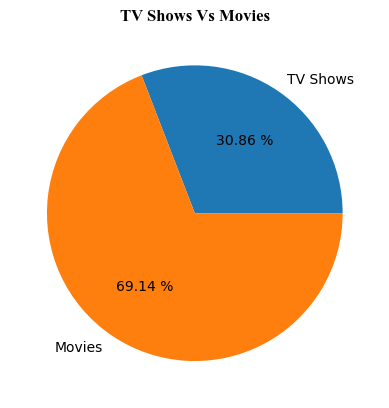

In [26]:
tv_shows=netflix_data.loc[netflix_data['type']=='TV Show'].count()[0]
Movies=netflix_data.loc[netflix_data['type']=='Movie'].count()[0]
labels=['TV Shows','Movies']
plt.title("TV Shows Vs Movies",fontdict={
    'fontfamily':'Times New Roman',
    'fontweight':'bold'
})
plt.pie([tv_shows,Movies],labels=labels,autopct='%.2f %%')
print(tv_shows,Movies)
plt.show()


TV Shows vs Movies: The pie chart shows the distribution of Movies and TV Shows in the Netflix dataset. Movies account for 69.14% of the total content, while TV Shows account for 30.86%. This indicates that Netflix has more than twice as many movies as TV shows in this dataset.

In [27]:
# plt.bar(['Tv_shows','Movies'],[tv_shows,Movies],label=labels,width=0.2)

#### Bar chart representing top 15 genres in netflix

In [28]:
netflix_data['genres'].value_counts()

genres
Documentaries                                                      334
Stand-Up Comedy                                                    321
Dramas, International Movies                                       320
Comedies, Dramas, International Movies                             243
Dramas, Independent Movies, International Movies                   215
                                                                  ... 
Anime Features, Music & Musicals                                     1
Comedies, Cult Movies, Sports Movies                                 1
Action & Adventure, Faith & Spirituality, Sci-Fi & Fantasy           1
TV Dramas, TV Sci-Fi & Fantasy, Teen TV Shows                        1
Stand-Up Comedy & Talk Shows, TV Mysteries, TV Sci-Fi & Fantasy      1
Name: count, Length: 491, dtype: int64

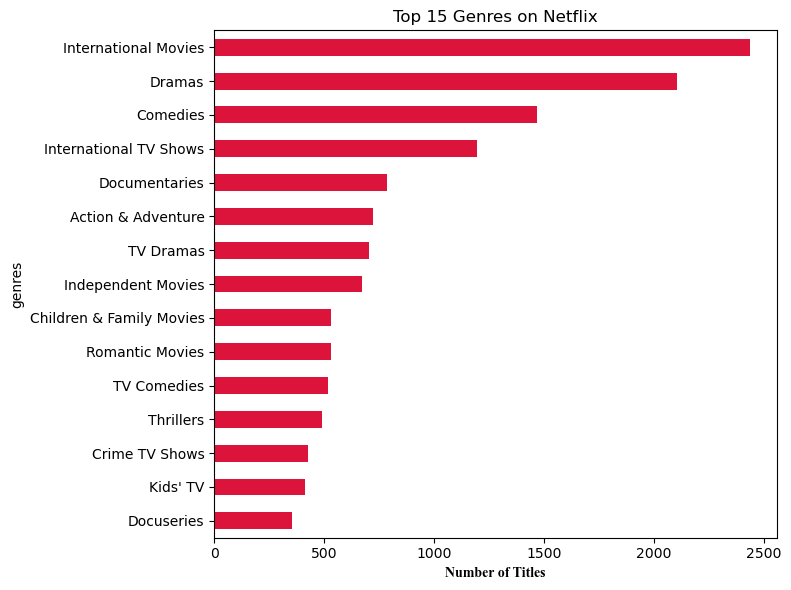

In [29]:
all_genres = netflix_data['genres'].str.split(', ').explode().value_counts()
top_genres = all_genres.head(15)
top_genres.sort_values().plot(kind='barh', figsize=(8,6), color='crimson')
plt.title('Top 15 Genres on Netflix')
plt.xlabel('Number of Titles',fontdict={
    'fontfamily':'Times New Roman',
    'fontweight':'bold'
})
plt.tight_layout()
plt.show()

Top 15 Genres on Netflix: The bar chart shows the 15 most common genres available in the Netflix dataset. International Movies are the most common genre, with around 2,400 titles, followed by Dramas with over 2,000 titles and Comedies with around 1,500 titles. International TV Shows and Documentaries are also among the more common genres. On the other hand, Docuseries, Kids' TV, and Crime TV Shows have comparatively fewer titles. Overall, the chart shows that Netflix has a strong presence of international content, dramas, and comedies.

#### Most common rating or rating with maximum count

In [30]:
netflix_data['rating'].value_counts().idxmax()

'TV-MA'

In [31]:
netflix_data.rating.value_counts()

rating
TV-MA       2868
TV-14       1928
TV-PG        804
R            665
PG-13        386
TV-Y         279
TV-Y7        270
PG           247
TV-G         194
NR            83
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64

### Ratings as per Netflix: 
Kids: TV-Y, TV-Y7, G, TV-G, PG, TV-PG 
Teens: PG-13, TV-14
Adults: R, TV-MA, NC-17

There are 3536 Adult shows,2314 Teen shows and 1839 Kids shows


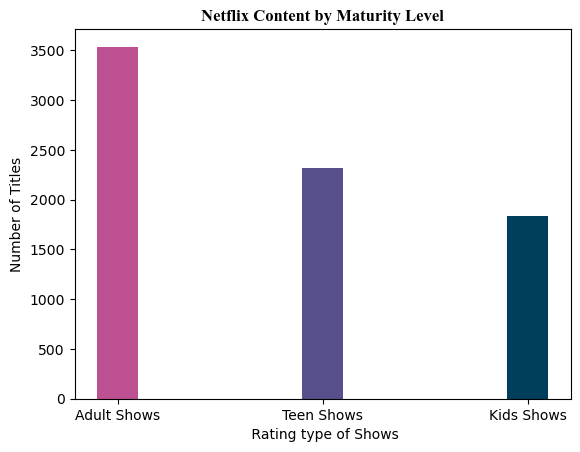

In [32]:
adults = ['TV-MA', 'R', 'NC-17']
teen = ['TV-14', 'PG-13']
kids = ['TV-Y', 'TV-Y7', 'TV-G', 'TV-PG', 'G', 'PG', 'TV-Y7-FV']

mature_shows=netflix_data['rating'].isin(adults).sum()
teen_shows=netflix_data['rating'].isin(teen).sum()
kids_shows=netflix_data['rating'].isin(kids).sum()
print(f"There are {mature_shows} Adult shows,{teen_shows} Teen shows and {kids_shows} Kids shows")

plt.bar(['Adult Shows','Teen Shows','Kids Shows'],[mature_shows,teen_shows,kids_shows],color=['#bc5090','#58508d','#003f5c'],width=0.2)
plt.title('Netflix Content by Maturity Level',fontdict={
    'fontfamily':'Times New Roman',
    'fontweight':'bold'
})
plt.xlabel(' Rating type of Shows')
plt.ylabel('Number of Titles')
plt.show()

Netflix Content by Maturity Level: The bar chart shows the number of Netflix titles classified into different maturity levels. Adult Shows have the highest number of titles, with around 3,500 titles. They are followed by Teen Shows, with around 2,300 titles, while Kids Shows have around 1,800 titles. This shows that Netflix has more adult-oriented content than teen and kids content in the analyzed dataset.

In [33]:
Adult_pct = mature_shows/len(netflix_data)*100
teen_pct = teen_shows/len(netflix_data)*100
kids_pct = kids_shows/len(netflix_data)*100
print(Adult_pct,teen_pct,kids_pct)


45.46740388324547 29.754404011829756 23.646650379323646


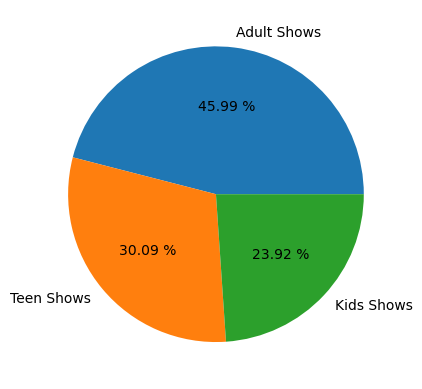

In [34]:
labels=['Adult Shows','Teen Shows','Kids Shows']
plt.pie([mature_shows,teen_shows,kids_shows],autopct='%.2f %%',labels=labels)
plt.show()

### Finding out average duration of Movies and TV shows

In [35]:
netflix_data.groupby('type')['duration'].mean().round()

type
Movie      99.0
TV Show     2.0
Name: duration, dtype: float64

In [36]:
netflix_data.groupby('type')['duration'].mean()

type
Movie      99.307978
TV Show     1.760833
Name: duration, dtype: float64

In [37]:
movies = netflix_data[netflix_data['type'] == 'Movie']
tvshows = netflix_data[netflix_data['type'] == 'TV Show']

### Average duration of movies

In [38]:
movies['duration'].mean().round()

np.float64(99.0)

### Average number of seasons TV shows have

In [39]:
tvshows['duration'].mean().round()

np.float64(2.0)

### Top 10 newly released movies in netflix

In [40]:
movies.iloc[movies['release_year'].sort_values(ascending=False)].head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...
2921,s3628,Movie,Life of An Outcast,Pawan K Shrivastava,"Ravi Bhushan Bhartiya, Shalini Mohan, Bhaskar ...",India,2019-02-25,2018,TV-PG,80,"Dramas, Independent Movies, International Movies",When authorities jail his son for rejecting re...


### Top 10 newly released TV shows in netflix

In [41]:
tvshows.iloc[tvshows['release_year'].sort_values(ascending=False)].head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...
6615,s6953,TV Show,The Twelve,Wouter Bouvijn,"Maaike Neuville, Charlotte De Bruyne, Tom Verm...",Belgium,2020-07-10,2019,TV-MA,1,"Crime TV Shows, International TV Shows, TV Dramas",Twelve jurors — ordinary people with struggles...


### Top 10 newly added Tv shows in netflix

In [42]:
tvshows.sort_values(by='date_added',ascending=False).head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
2749,s3473,TV Show,Kuroko's Basketball,Not Specfied,"Kensho Ono, Yuki Ono, Chiwa Saito, Yoshimasa H...",Japan,2021-01-15,2013,TV-MA,1,"Anime Series, International TV Shows, Teen TV ...",Five middle school basketball stars went to se...
869,s1781,TV Show,Disenchantment,Not Specfied,"Abbi Jacobson, Eric André, Nat Faxon, John DiM...",United States,2021-01-15,2021,TV-14,3,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","Princess duties call, but she'd rather be drin..."
6262,s6635,TV Show,The Magicians,Not Specfied,"Jason Ralph, Arjun Gupta, Hale Appleman, Stell...","United States, Canada",2021-01-15,2020,TV-MA,5,"TV Dramas, TV Sci-Fi & Fantasy",When grad student Quentin Coldwater enters a c...
7767,s981,TV Show,Bling Empire,Not Specfied,Not Specfied,Unknown,2021-01-15,2021,TV-MA,1,Reality TV,Follow LA's wildly wealthy Asian and Asian Ame...
250,s1223,TV Show,Carmen Sandiego,Not Specfied,"Gina Rodriguez, Finn Wolfhard, Abby Trott, Mic...",United States,2021-01-15,2021,TV-Y7,4,"Kids' TV, TV Thrillers","A master thief who uses her skills for good, C..."


### Top 10 newly added Movies in netflix

In [43]:
movies.sort_values(by='date_added',ascending=False).head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
4513,s5060,Movie,Radium Girls,"Lydia Dean Pilcher, Ginny Mohler","Joey King, Abby Quinn, Cara Seymour, Scott She...",United States,2021-01-16,2018,TV-14,103,"Dramas, Independent Movies",When the women at a radium factory begin to fa...
1179,s206,Movie,A Monster Calls,J.A. Bayona,"Lewis MacDougall, Sigourney Weaver, Felicity J...","United Kingdom, Spain, United States",2021-01-16,2016,PG-13,108,"Dramas, Sci-Fi & Fantasy","Overwhelmed by his mother’s illness, a young b..."
750,s1674,Movie,Death of Me,Darren Lynn Bousman,"Maggie Q, Luke Hemsworth, Alex Essoe, Ingkarat...","United States, Thailand",2021-01-16,2020,R,94,Horror Movies,"With no memory of the previous night, a vacati..."
7384,s7645,Movie,Wish You,Sung Do-jun,"Kang In-soo, Lee Sang, Soo-bin",Unknown,2021-01-15,2021,TV-PG,102,"Dramas, International Movies, LGBTQ Movies","Singing and dreaming together, a talented sing..."
4125,s4711,Movie,Outside the Wire,Mikael Håfström,"Anthony Mackie, Damson Idris, Emily Beecham, M...",Unknown,2021-01-15,2021,R,116,Action & Adventure,"In the near future, a drone pilot sent into a ..."
4294,s4864,Movie,Pinkfong & Baby Shark's Space Adventure,Byeon Hee-sun,"Jo Kyoung-i, Kim Seo-yeong, Kim Eun-ah, Jeong ...",Unknown,2021-01-15,2019,TV-Y,65,Children & Family Movies,"Joined by new friends from other planets, Pink..."
2002,s2800,Movie,Hook,Steven Spielberg,"Dustin Hoffman, Robin Williams, Julia Roberts,...",United States,2021-01-15,1991,PG,142,Children & Family Movies,"Peter Pan, now grown up and a workaholic, must..."
6914,s7221,Movie,Tribhanga - Tedhi Medhi Crazy,Renuka Shahane,"Kajol, Tanvi Azmi, Mithila Palkar, Kunaal Roy ...",Unknown,2021-01-15,2021,TV-MA,96,"Dramas, International Movies","When her estranged mother falls into a coma, a..."
927,s1833,Movie,Double Dad,Cris D'Amato,"Maisa Silva, Eduardo Moscovis, Marcelo Médici,...",Brazil,2021-01-15,2020,TV-G,105,"Children & Family Movies, Comedies, Dramas","While her mom is away, a teen sneaks out of th..."
6640,s6976,Movie,The Vanished,Peter Facinelli,"Thomas Jane, Anne Heche, Jason Patric, John D....",United States,2021-01-15,2020,R,115,Thrillers,When their daughter disappears during a family...


#### Most common genre in different countries

In [44]:
exploded=netflix_data.assign(
    country=netflix_data['country'].str.split(', ' ),
    genres=netflix_data['genres'].str.split(', ')
).explode('country').explode('genres')
top_genre = exploded.groupby('country')['genres'].agg(lambda x : x.value_counts().idxmax())
top_genre

country
Afghanistan            Documentaries
Albania                       Dramas
Algeria                       Dramas
Angola            Action & Adventure
Argentina       International Movies
                        ...         
Vatican City           Documentaries
Venezuela              Documentaries
Vietnam         International Movies
West Germany    International Movies
Zimbabwe        International Movies
Name: genres, Length: 122, dtype: object

#### Top 10 directors with most titles  

In [45]:
director_data=netflix_data['director'].value_counts().sort_values(ascending=False).head(10)
director_data

director
Not Specfied              2379
Raúl Campos, Jan Suter      18
Marcus Raboy                16
Jay Karas                   14
Cathy Garcia-Molina         13
Martin Scorsese             12
Youssef Chahine             12
Jay Chapman                 12
Steven Spielberg            10
David Dhawan                 9
Name: count, dtype: int64

In [46]:
# director_data.sort_values().plot(kind='bar', figsize=(8,6), color='crimson')
# plt.xlabel('Director')
# plt.ylabel('Number of titles')

In [47]:
!git add .

In [48]:
!git commit -m "Updated file"


[main 8f3e662] Updated file
 2 files changed, 594 insertions(+), 63 deletions(-)


In [49]:
!git push origin

To https://github.com/binita21/Netfix_Data_analysis.git
   360ba4f..8f3e662  main -> main


In [50]:
netflix_data['release_year'].value_counts().idxmax()

np.int64(2018)

In [51]:
# top_year = netflix_data['release_year'].value_counts().idxmax()
# top_count = netflix_data['release_year'].value_counts().max()

# print(f"{top_year} had the most releases, with {top_count} titles.")

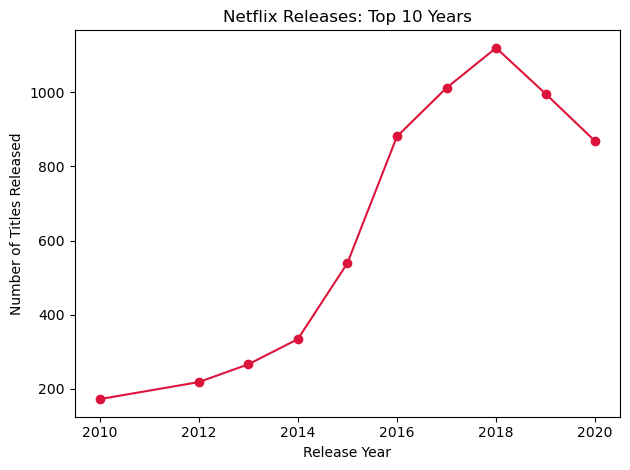

In [52]:
release_count = netflix_data['release_year'].value_counts().sort_values(ascending=False).head(10).sort_index()
release_count.plot(kind='line', marker='o', color='crimson')
plt.title('Netflix Releases: Top 10 Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Released')
plt.tight_layout()
plt.show()

The line chart shows the distribution of Netflix content released across the top 10 release years. The highest number of titles was released in 2018, while the lowest number was released in 2010. The number of titles increased steadily from 2010 to 2018, reaching a peak of around 1,100 titles. However, after 2018, the number of releases began to decline, with around 1,000 titles in 2019 and approximately 870 titles in 2020. Overall, the chart shows a strong growth in Netflix content releases from 2010 to 2018, followed by a decline in the subsequent years.

In [53]:
netflix_data.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genres', 'description'],
      dtype='object')

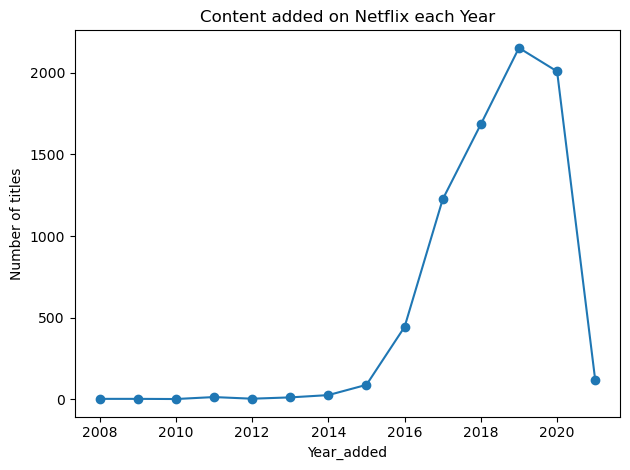

In [54]:
netflix_data['year_added'] = netflix_data.date_added.dt.year
added_peryear = netflix_data.year_added.value_counts().sort_index()
added_peryear.plot(kind='line',marker='o')
plt.title("Content added on Netflix each Year")
plt.xlabel("Year_added")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

The line chart shows the distribution of content added to Netflix each year. The number of titles added remained relatively low from 2008 to 2014, but increased significantly from 2015 onward. Netflix added the highest number of titles in 2019, with more than 2,000 titles. After reaching this peak, the number of titles added decreased in 2020 and dropped sharply in 2021.

In [96]:
content_type_year = (
    netflix_data.groupby(['year_added', 'type'])
    .size()
    .unstack(fill_value=0)
)



In [66]:
content_type_year

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,6
2015,58,30
2016,258,185


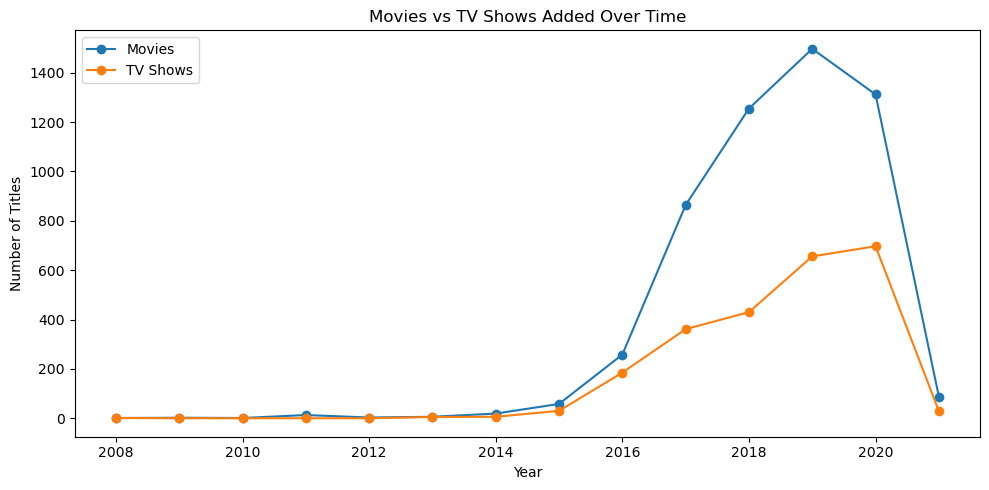

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(
    content_type_year.index,
    content_type_year['Movie'],
    marker='o',
    label='Movies'
)

plt.plot(
    content_type_year.index,
    content_type_year['TV Show'],
    marker='o',
    label='TV Shows'
)

plt.title("Movies vs TV Shows Added Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.legend()

plt.tight_layout()
plt.show()

In [98]:
!git add .
!git commit -m "Netflix data file updated"
!git push origin
    

[main 4e4056c] Netflix data file updated
 1 file changed, 189 insertions(+), 35 deletions(-)


To https://github.com/binita21/Netfix_Data_analysis.git
   8f3e662..4e4056c  main -> main
